# CSI-5005 Mini Project: Climate Seasonality and Anomaly Tracker
## Part 1: Exploratory Data Analysis (EDA), Statistical Profiling & Mathematical Pipeline

**Dataset:** Daily Minimum Temperatures in Melbourne, Australia (1981–1990) (`melbourne_temp.csv`)  
**CSI-5005 Syllabus Topics Covered:**
- NumPy, Pandas, SciPy, Matplotlib & Seaborn
- Exploratory Data Analysis (EDA) & Data Cleaning
- Sampling Techniques, Statistical Variables & Grouped Frequency Distributions
- Comparative Distribution Plots (Bar plots, Pie charts, Step-type Histograms, KDE, Box & Strip plots)
- Fast Fourier Transform (FFT) & Inverse FFT Filtering (`scipy.fft`)
- Non-Linear Curve Optimization (`scipy.optimize.curve_fit` — Levenberg-Marquardt)
- Residual Analysis & Statistical Anomaly Detection (Z-Score & IQR)


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.fft import fft, ifft, fftfreq
from scipy.optimize import curve_fit

# Configure plot aesthetics
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 10)
pd.set_option("display.precision", 3)

print("Libraries imported successfully.")


Libraries imported successfully.


---
## 1. Raw File Audit & Data Cleaning
Before running any mathematical operations, we audit the raw CSV file (`melbourne_temp.csv`) for structural anomalies, non-numeric corruption, and calendar gaps that would break uniform-step FFT assumptions.


In [2]:
FILE_PATH = "melbourne_temp.csv"

# 1. Inspect raw lines to detect corrupted footer/header lines
with open(FILE_PATH, "r", encoding="utf-8") as f:
    raw_lines = f.readlines()

print(f"Total raw lines in file: {len(raw_lines)}")
print("First 3 lines:")
for line in raw_lines[:3]:
    print("  ", repr(line))
print("Last 4 lines:")
for line in raw_lines[-4:]:
    print("  ", repr(line))


Total raw lines in file: 3654
First 3 lines:
   '"Date","Daily minimum temperatures in Melbourne, Australia, 1981-1990"\n'
   '"1981-01-01",20.7\n'
   '"1981-01-02",17.9\n'
Last 4 lines:
   '"1990-12-31",13.0\n'
   '\n'
   'Daily minimum temperatures in Melbourne, Australia, 1981-1990\n'
   '\n'


In [3]:
# 2. Load CSV safely (skipping the malformed footer line with extra commas)
df_raw = pd.read_csv(FILE_PATH, on_bad_lines="skip")
print("Original column names:", df_raw.columns.tolist())

# Standardize column names
df_raw.columns = ["Date", "Temp"]
print(f"Loaded shape: {df_raw.shape}")
print("Raw data types:")
print(df_raw.dtypes)

# 3. Identify dirty / non-numeric temperature strings (e.g., '?0.2')
dirty_temp_mask = pd.to_numeric(df_raw["Temp"], errors="coerce").isna()
print(f"Found {dirty_temp_mask.sum()} corrupted temperature entries:")
display(df_raw[dirty_temp_mask])

# Check for invalid dates
invalid_date_mask = pd.to_datetime(df_raw["Date"], errors="coerce").isna()
print(f"Found {invalid_date_mask.sum()} invalid date entries.")


Original column names: ['Date', 'Daily minimum temperatures in Melbourne, Australia, 1981-1990']
Loaded shape: (3650, 2)
Raw data types:
Date    str
Temp    str
dtype: object
Found 3 corrupted temperature entries:


,Date,Temp
565,1982-07-20,?0.2
566,1982-07-21,?0.8
1290,1984-07-14,?0.1


Found 0 invalid date entries.


In [4]:
# 4. Clean dataset, parse types, and check for missing calendar days (Leap Years)
df = df_raw.copy()
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Temp"] = df["Temp"].astype(str).str.replace(r"[^0-9.-]", "", regex=True)
df["Temp"] = pd.to_numeric(df["Temp"], errors="coerce")
df = df.dropna().set_index("Date").sort_index()

# Verify daily continuity (required for uniform time-step FFT)
full_date_range = pd.date_range(df.index.min(), df.index.max(), freq="D")
missing_dates = full_date_range.difference(df.index)

print(f"Date Range        : {df.index.min().date()} to {df.index.max().date()}")
print(f"Expected Days     : {len(full_date_range)}")
print(f"Observed Days     : {len(df)}")
print(f"Missing Dates ({len(missing_dates)}) : {[d.strftime('%Y-%m-%d') for d in missing_dates]}")

# Reindex to continuous daily frequency and linearly interpolate the 2 missing leap-year days
df = df.reindex(full_date_range)
df.index.name = "Date"
df["Temp"] = df["Temp"].interpolate(method="linear")

# Add calendar & Southern Hemisphere seasonal features
def map_melbourne_season(month):
    if month in [12, 1, 2]:
        return "Summer"
    elif month in [3, 4, 5]:
        return "Autumn"
    elif month in [6, 7, 8]:
        return "Winter"
    return "Spring"

SEASON_ORDER = ["Summer", "Autumn", "Winter", "Spring"]
df["Year"] = df.index.year
df["Month"] = df.index.month
df["Month_Name"] = df.index.strftime("%b")
df["Season"] = pd.Categorical(df["Month"].map(map_melbourne_season), categories=SEASON_ORDER, ordered=True)
df["Half_Period"] = np.where(df["Year"] <= 1985, "1981–1985", "1986–1990")

print(f"Cleaned continuous DataFrame shape: {df.shape}")
print("Null values remaining:", df["Temp"].isna().sum())
display(df.head())


Date Range        : 1981-01-01 to 1990-12-31
Expected Days     : 3652
Observed Days     : 3650
Missing Dates (2) : ['1984-12-31', '1988-12-31']
Cleaned continuous DataFrame shape: (3652, 6)
Null values remaining: 0


,Temp,Year,Month,Month_Name,Season,Half_Period
Date,,,,,,
1981-01-01,20.7,1981,1,Jan,Summer,1981–1985
1981-01-02,17.9,1981,1,Jan,Summer,1981–1985
1981-01-03,18.8,1981,1,Jan,Summer,1981–1985
1981-01-04,14.6,1981,1,Jan,Summer,1981–1985
1981-01-05,15.8,1981,1,Jan,Summer,1981–1985


---
## 2. Descriptive Statistics & Distribution Profiling
Using NumPy and `scipy.stats`, we compute central tendency, dispersion, shape parameters (skewness & kurtosis), and test whether the raw temperature distribution is Gaussian.


In [5]:
temps = df["Temp"].values

q1, median, q3 = np.percentile(temps, [25, 50, 75])
iqr = q3 - q1
mode_res = stats.mode(temps, keepdims=True)
skewness = stats.skew(temps)
kurtosis = stats.kurtosis(temps)  # Excess kurtosis (Normal = 0)
dagostino_stat, dagostino_p = stats.normaltest(temps)

summary_stats = pd.DataFrame({
    "Metric": [
        "Count (Days)", "Mean (°C)", "Median (°C)", "Mode (°C)",
        "Std Deviation (°C)", "Variance (°C²)", "Minimum (°C)", "Maximum (°C)",
        "Range (°C)", "Q1 (25th Percentile)", "Q3 (75th Percentile)", "IQR (°C)",
        "Skewness", "Excess Kurtosis", "D'Agostino Normality p-value"
    ],
    "Value": [
        len(temps), np.mean(temps), median, mode_res.mode[0],
        np.std(temps, ddof=1), np.var(temps, ddof=1), np.min(temps), np.max(temps),
        np.ptp(temps), q1, q3, iqr,
        skewness, kurtosis, dagostino_p
    ]
})
display(summary_stats)

# Seasonal summary table
print("Summary Statistics by Melbourne Season (Southern Hemisphere):")
seasonal_summary = df.groupby("Season", observed=False)["Temp"].agg(
    Count="count", Mean="mean", Median="median", Std="std", Min="min", Max="max")
display(seasonal_summary)


,Metric,Value
0,Count (Days),3.652e+03
1,Mean (°C),1.118e+01
2,Median (°C),1.100e+01
3,Mode (°C),1.000e+01
4,Std Deviation (°C),4.071e+00
5,Variance (°C²),1.658e+01
6,Minimum (°C),0.000e+00
7,Maximum (°C),2.630e+01
8,Range (°C),2.630e+01
9,Q1 (25th Percentile),8.300e+00


Summary Statistics by Melbourne Season (Southern Hemisphere):


,Count,Mean,Median,Std,Min,Max
Season,,,,,,
Summer,902,14.734,14.5,2.775,8.2,26.3
Autumn,920,12.174,12.0,3.588,2.1,22.4
Winter,920,7.287,7.5,2.583,0.0,14.3
Spring,910,10.585,10.4,3.157,3.0,24.3


---
## 3. Grouped Frequency Distributions & Sampling Verification
Directly applying CSI-5005 statistical lab concepts:
1. Build a **grouped frequency distribution table** using $2^\circ\text{C}$ class intervals.
2. Compare **Simple Random Sampling (SRS)** against **Stratified Sampling (by Season)** at $n = 365$ (10% of population) to evaluate estimator bias.


In [6]:
# Grouped Frequency Distribution Table (2°C bins)
bins = np.arange(0, 28, 2)
bin_labels = [f"{b}–{b+2} °C" for b in bins[:-1]]
df["Temp_Bin"] = pd.cut(df["Temp"], bins=bins, right=False, labels=bin_labels)

freq_table = df["Temp_Bin"].value_counts().sort_index().to_frame(name="Frequency")
freq_table["Relative_Freq (%)"] = (freq_table["Frequency"] / len(df) * 100).round(2)
freq_table["Cumulative_Freq"] = freq_table["Frequency"].cumsum()
freq_table["Cumulative_Rel_Freq (%)"] = (freq_table["Cumulative_Freq"] / len(df) * 100).round(2)

print("Grouped Frequency Distribution Table:")
display(freq_table)


Grouped Frequency Distribution Table:


,Frequency,Relative_Freq (%),Cumulative_Freq,Cumulative_Rel_Freq (%)
Temp_Bin,,,,
0–2 °C,28,0.77,28,0.77
2–4 °C,84,2.30,112,3.07
4–6 °C,236,6.46,348,9.53
6–8 °C,471,12.90,819,22.43
8–10 °C,623,17.06,1442,39.49
10–12 °C,674,18.46,2116,57.94
12–14 °C,617,16.89,2733,74.84
14–16 °C,466,12.76,3199,87.60
16–18 °C,273,7.48,3472,95.07


In [7]:
# Sampling Comparison: Simple Random Sampling vs. Stratified Sampling (n = 365)
SAMPLE_N = 365
srs_sample = df.sample(n=SAMPLE_N, random_state=42)
strat_sample = pd.concat([
    grp.sample(frac=SAMPLE_N / len(df), random_state=42)
    for _, grp in df.groupby("Season", observed=False)
])

sampling_comparison = pd.DataFrame({
    "Dataset": ["Full Population (N=3652)", f"Simple Random Sample (n={len(srs_sample)})", f"Stratified Sample (n={len(strat_sample)})"],
    "Mean (°C)": [df["Temp"].mean(), srs_sample["Temp"].mean(), strat_sample["Temp"].mean()],
    "Median (°C)": [df["Temp"].median(), srs_sample["Temp"].median(), strat_sample["Temp"].median()],
    "Std Dev (°C)": [df["Temp"].std(), srs_sample["Temp"].std(), strat_sample["Temp"].std()],
    "Abs Mean Error (°C)": [
        0.0,
        abs(srs_sample["Temp"].mean() - df["Temp"].mean()),
        abs(strat_sample["Temp"].mean() - df["Temp"].mean())
    ]
})
print("Population vs. Sampling Estimators:")
display(sampling_comparison)

print("Seasonal Proportions Check (%):")
prop_df = pd.DataFrame({
    "Population (%)": (df["Season"].value_counts(normalize=True) * 100).round(2),
    "SRS (%)": (srs_sample["Season"].value_counts(normalize=True) * 100).round(2),
    "Stratified (%)": (strat_sample["Season"].value_counts(normalize=True) * 100).round(2),
})
display(prop_df)


Population vs. Sampling Estimators:


,Dataset,Mean (°C),Median (°C),Std Dev (°C),Abs Mean Error (°C)
0,Full Population (N=3652),11.180,11.0,4.071,0.000
1,Simple Random Sample (n=365),11.098,11.0,4.226,0.082
2,Stratified Sample (n=365),11.247,11.2,4.321,0.067


Seasonal Proportions Check (%):


,Population (%),SRS (%),Stratified (%)
Season,,,
Summer,24.70,21.64,24.66
Autumn,25.19,26.85,25.21
Winter,25.19,28.49,25.21
Spring,24.92,23.01,24.93


---
## 4. Exploratory Data Analysis (EDA) & Comparative Visualisations
Visualising the time series, temperature categories, and comparing distributions across Southern Hemisphere seasons and 5-year periods (`1981–1985` vs `1986–1990`) using bar plots, pie charts, step-type histograms, KDE plots, box plots, and strip plots.


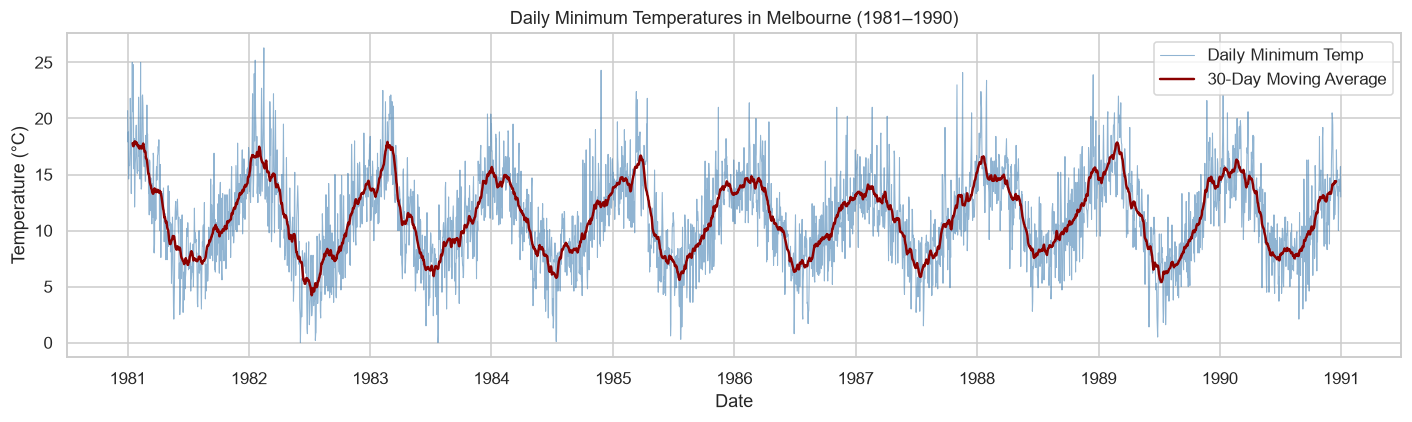

In [8]:
# 4.1 Raw Time Series with 30-Day Rolling Average
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(df.index, df["Temp"], color="steelblue", alpha=0.6, linewidth=0.7, label="Daily Minimum Temp")
ax.plot(df.index, df["Temp"].rolling(30, center=True).mean(), color="darkred", linewidth=1.6, label="30-Day Moving Average")
ax.set_title("Daily Minimum Temperatures in Melbourne (1981–1990)")
ax.set_xlabel("Date")
ax.set_ylabel("Temperature (°C)")
ax.legend()
plt.tight_layout()
plt.show()


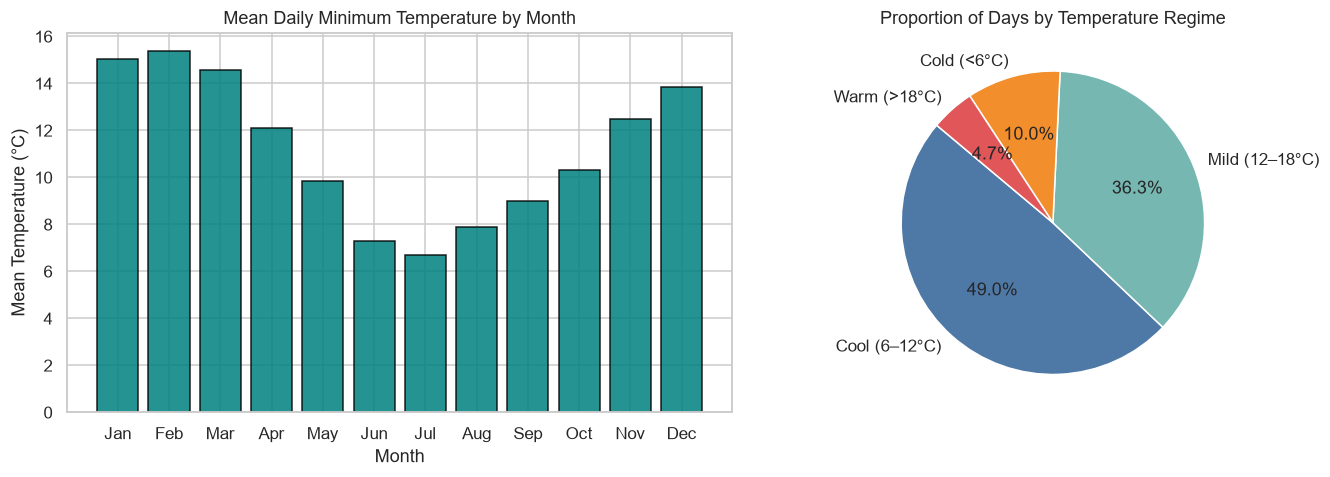

In [9]:
# 4.2 Monthly Mean Bar Plot & Temperature Regime Pie Chart
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Bar plot of average temperature by month
month_order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
monthly_avg = df.groupby("Month_Name")["Temp"].mean().reindex(month_order)
axes[0].bar(monthly_avg.index, monthly_avg.values, color="teal", edgecolor="black", alpha=0.85)
axes[0].set_title("Mean Daily Minimum Temperature by Month")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Mean Temperature (°C)")

# Pie chart of temperature regimes
regimes = pd.cut(
    df["Temp"],
    bins=[-1, 6, 12, 18, 30],
    labels=["Cold (<6°C)", "Cool (6–12°C)", "Mild (12–18°C)", "Warm (>18°C)"]
)
regime_counts = regimes.value_counts()
axes[1].pie(
    regime_counts.values,
    labels=regime_counts.index,
    autopct="%1.1f%%",
    startangle=140,
    colors=["#4e79a7", "#76b7b2", "#f28e2b", "#e15759"]
)
axes[1].set_title("Proportion of Days by Temperature Regime")

plt.tight_layout()
plt.show()


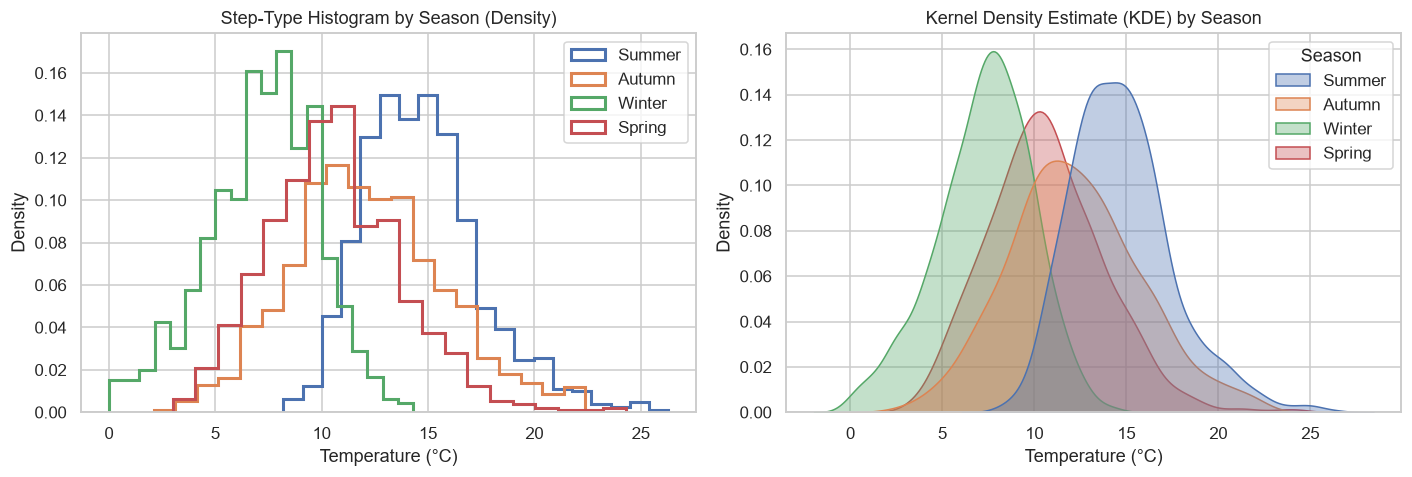

In [10]:
# 4.3 Comparing Frequency Distributions: Step-Type Histogram & KDE Plot by Season
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for season in SEASON_ORDER:
    subset = df[df["Season"] == season]["Temp"]
    axes[0].hist(subset, bins=20, histtype="step", linewidth=2, density=True, label=season)
axes[0].set_title("Step-Type Histogram by Season (Density)")
axes[0].set_xlabel("Temperature (°C)")
axes[0].set_ylabel("Density")
axes[0].legend()

sns.kdeplot(data=df, x="Temp", hue="Season", fill=True, common_norm=False, alpha=0.35, ax=axes[1])
axes[1].set_title("Kernel Density Estimate (KDE) by Season")
axes[1].set_xlabel("Temperature (°C)")

plt.tight_layout()
plt.show()


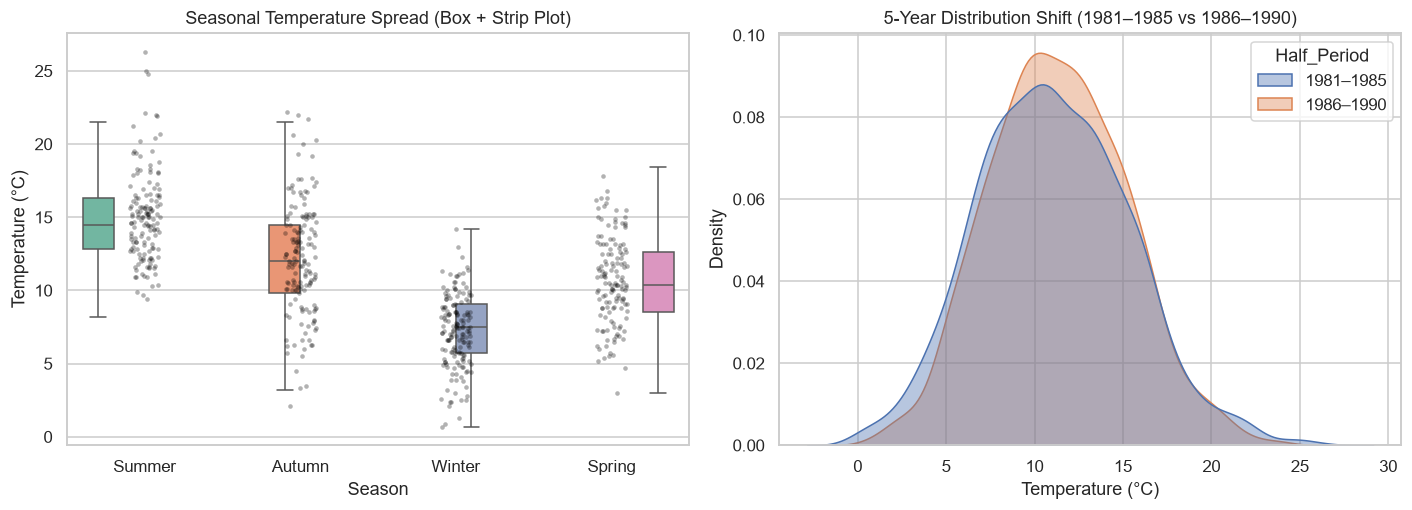

In [11]:
# 4.4 Box Plot + Strip Plot (Season Variance) & 5-Year Period Comparison
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Box + Strip plot by season (subsample strip plot for visual clarity)
sns.boxplot(data=df, x="Season", y="Temp", hue="Season", palette="Set2", legend=False, ax=axes[0], showfliers=False)
sns.stripplot(
    data=df.sample(600, random_state=42),
    x="Season", y="Temp", color="black", alpha=0.3, size=3, jitter=True, ax=axes[0]
)
axes[0].set_title("Seasonal Temperature Spread (Box + Strip Plot)")
axes[0].set_ylabel("Temperature (°C)")

# 5-Year Half Period KDE comparison (1981–1985 vs 1986–1990)
sns.kdeplot(data=df, x="Temp", hue="Half_Period", fill=True, common_norm=False, alpha=0.4, ax=axes[1])
axes[1].set_title("5-Year Distribution Shift (1981–1985 vs 1986–1990)")
axes[1].set_xlabel("Temperature (°C)")

plt.tight_layout()
plt.show()


---
## 5. Time-to-Frequency Domain Analysis (Fast Fourier Transform)
We apply the 1D Discrete Fourier Transform via `scipy.fft`:
$$X_k = \sum_{n=0}^{N-1} x_n e^{-i 2\pi k n / N}$$
This decomposes the noisy daily time series into constituent sinusoidal frequencies, allowing us to mathematically isolate the dominant seasonal period and demonstrate low-pass noise filtering via Inverse FFT (`ifft`).


Dominant Period    : 365.20 days (Expected annual cycle: ~365.25 days)
Dominant Frequency : 0.002738 cycles/day
Peak FFT Amplitude : 4.211 °C


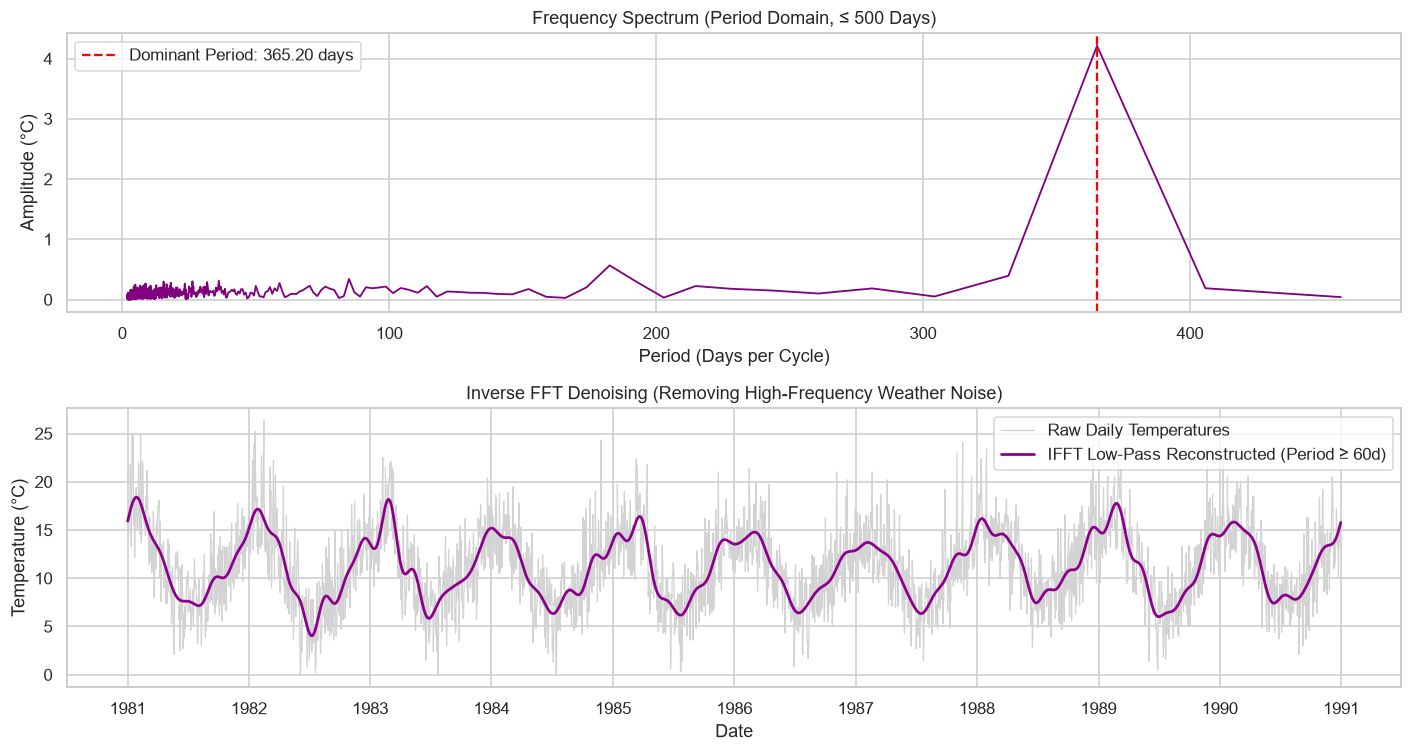

In [12]:
y = df["Temp"].values
n = len(y)
y_mean = np.mean(y)
y_centered = y - y_mean

# Compute FFT and frequencies (cycles per day)
yf = fft(y_centered)
xf = fftfreq(n, d=1.0)

# Extract positive frequencies and single-sided amplitudes
pos_mask = xf > 0
freqs = xf[pos_mask]
amplitudes = np.abs(yf[pos_mask]) * (2.0 / n)
periods = 1.0 / freqs

dominant_idx = np.argmax(amplitudes)
dominant_period = periods[dominant_idx]
dominant_amp = amplitudes[dominant_idx]

print(f"Dominant Period    : {dominant_period:.2f} days (Expected annual cycle: ~365.25 days)")
print(f"Dominant Frequency : {freqs[dominant_idx]:.6f} cycles/day")
print(f"Peak FFT Amplitude : {dominant_amp:.3f} °C")

# Low-pass Inverse FFT Filter (remove weather fluctuations shorter than 60 days)
CUTOFF_DAYS = 60
yf_filtered = yf.copy()
yf_filtered[np.abs(xf) > (1.0 / CUTOFF_DAYS)] = 0
y_ifft_smooth = np.real(ifft(yf_filtered)) + y_mean

fig, axes = plt.subplots(2, 1, figsize=(13, 7))

# Plot Power Spectral Density in Period Domain
display_mask = periods <= 500
axes[0].plot(periods[display_mask], amplitudes[display_mask], color="purple", linewidth=1.2)
axes[0].axvline(dominant_period, color="red", linestyle="--", label=f"Dominant Period: {dominant_period:.2f} days")
axes[0].set_title("Frequency Spectrum (Period Domain, ≤ 500 Days)")
axes[0].set_xlabel("Period (Days per Cycle)")
axes[0].set_ylabel("Amplitude (°C)")
axes[0].legend()

# Plot IFFT Filtered Signal vs Raw Data
axes[1].plot(df.index, y, color="lightgrey", linewidth=0.8, label="Raw Daily Temperatures")
axes[1].plot(df.index, y_ifft_smooth, color="darkmagenta", linewidth=1.8, label=f"IFFT Low-Pass Reconstructed (Period ≥ {CUTOFF_DAYS}d)")
axes[1].set_title("Inverse FFT Denoising (Removing High-Frequency Weather Noise)")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Temperature (°C)")
axes[1].legend()

plt.tight_layout()
plt.show()


---
## 6. Non-Linear Curve Optimization (Levenberg-Marquardt)
Using the dominant frequency $\omega = 2\pi / T_{\text{dom}}$ extracted by the FFT, we fit the sinusoidal seasonal baseline model:
$$f(t) = A \sin(\omega t + \phi) + C$$
using `scipy.optimize.curve_fit` (Levenberg-Marquardt non-linear least squares).


In [13]:
t = np.arange(n)
omega = 2.0 * np.pi / dominant_period

def sine_model(t, A, phase, C):
    return A * np.sin(omega * t + phase) + C

initial_guess = [5.0, 0.0, y_mean]
popt, pcov = curve_fit(sine_model, t, y, p0=initial_guess)
opt_A, opt_phase, opt_C = popt
param_std_errors = np.sqrt(np.diag(pcov))

y_fit = sine_model(t, opt_A, opt_phase, opt_C)
residuals = y - y_fit

rmse = np.sqrt(np.mean(residuals ** 2))
r_squared = 1.0 - (np.sum(residuals ** 2) / np.sum((y - y_mean) ** 2))

opt_summary = pd.DataFrame({
    "Parameter": ["Amplitude (A)", "Phase Shift (φ)", "Vertical Offset (C)"],
    "Initial Guess": initial_guess,
    "Optimized Value": popt,
    "Std Error": param_std_errors
})
display(opt_summary)
print(f"Model Goodness-of-Fit -> RMSE: {rmse:.3f} °C | R²: {r_squared:.4f}")


,Parameter,Initial Guess,Optimized Value,Std Error
0,Amplitude (A),5.00,4.211,0.065
1,Phase Shift (φ),0.00,1.142,0.015
2,Vertical Offset (C),11.18,11.180,0.046


Model Goodness-of-Fit -> RMSE: 2.776 °C | R²: 0.5351


---
## 7. Residual Analysis & Anomaly Isolation
Subtracting the optimized seasonal curve from the raw observations yields the daily **residuals** $r_t = y_t - f(t)$.  
We verify the residual distribution and isolate extreme weather anomalies using both **Z-Score ($|Z| > 2.5$)** and **Interquartile Range (IQR)** bounds.


Residual Mean: -0.0000 °C | Residual Std Dev: 2.7758 °C
Z-Score Anomalies (|Z| > 2.5): 60 (Hot: 50, Cold: 10)
IQR Residual Outliers (1.5x IQR): 31


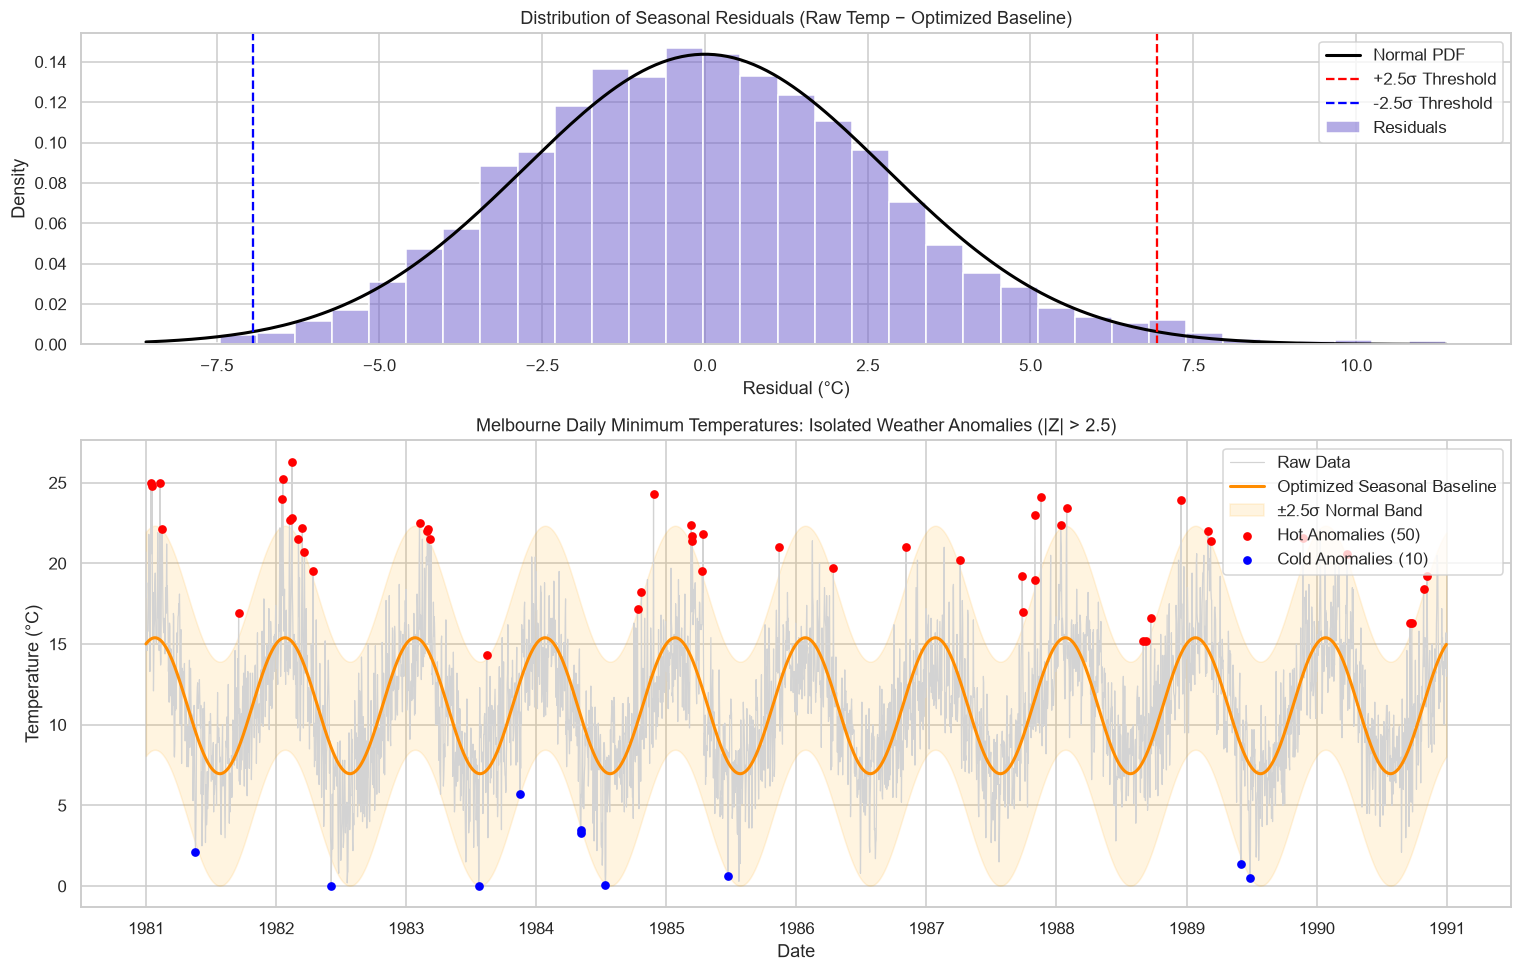

In [14]:
res_mean = np.mean(residuals)
res_std = np.std(residuals)
z_scores = (residuals - res_mean) / res_std

df["Fitted_Baseline"] = y_fit
df["Residual"] = residuals
df["Z_Score"] = z_scores

# Z-Score threshold
Z_THRESHOLD = 2.5
df["Anomaly_Z"] = np.where(
    df["Z_Score"] > Z_THRESHOLD, "Hot Anomaly",
    np.where(df["Z_Score"] < -Z_THRESHOLD, "Cold Anomaly", "Normal")
)

# IQR threshold on residuals for cross-verification
r_q1, r_q3 = np.percentile(residuals, [25, 75])
r_iqr = r_q3 - r_q1
iqr_outliers = (residuals < (r_q1 - 1.5 * r_iqr)) | (residuals > (r_q3 + 1.5 * r_iqr))

print(f"Residual Mean: {res_mean:.4f} °C | Residual Std Dev: {res_std:.4f} °C")
print(f"Z-Score Anomalies (|Z| > {Z_THRESHOLD}): {(df['Anomaly_Z'] != 'Normal').sum()} "
      f"(Hot: {(df['Anomaly_Z'] == 'Hot Anomaly').sum()}, Cold: {(df['Anomaly_Z'] == 'Cold Anomaly').sum()})")
print(f"IQR Residual Outliers (1.5x IQR): {iqr_outliers.sum()}")

# Plot Residual Distribution & Final Annotated Anomaly Chart
fig, axes = plt.subplots(2, 1, figsize=(14, 9), gridspec_kw={"height_ratios": [1, 1.5]})

# Residual Histogram + Normal Fit
sns.histplot(residuals, bins=35, stat="density", color="slateblue", alpha=0.5, ax=axes[0], label="Residuals")
x_grid = np.linspace(residuals.min(), residuals.max(), 200)
axes[0].plot(x_grid, stats.norm.pdf(x_grid, res_mean, res_std), color="black", linewidth=2, label="Normal PDF")
axes[0].axvline(res_mean + Z_THRESHOLD * res_std, color="red", linestyle="--", label=f"+{Z_THRESHOLD}σ Threshold")
axes[0].axvline(res_mean - Z_THRESHOLD * res_std, color="blue", linestyle="--", label=f"-{Z_THRESHOLD}σ Threshold")
axes[0].set_title("Distribution of Seasonal Residuals (Raw Temp − Optimized Baseline)")
axes[0].set_xlabel("Residual (°C)")
axes[0].legend()

# Final Time Series with Anomalies Highlighted
upper_bound = y_fit + Z_THRESHOLD * res_std
lower_bound = y_fit - Z_THRESHOLD * res_std
hot_df = df[df["Anomaly_Z"] == "Hot Anomaly"]
cold_df = df[df["Anomaly_Z"] == "Cold Anomaly"]

axes[1].plot(df.index, y, color="lightgrey", linewidth=0.8, label="Raw Data")
axes[1].plot(df.index, y_fit, color="darkorange", linewidth=2.0, label="Optimized Seasonal Baseline")
axes[1].fill_between(df.index, lower_bound, upper_bound, color="orange", alpha=0.12, label=f"±{Z_THRESHOLD}σ Normal Band")
axes[1].scatter(hot_df.index, hot_df["Temp"], color="red", s=22, zorder=5, label=f"Hot Anomalies ({len(hot_df)})")
axes[1].scatter(cold_df.index, cold_df["Temp"], color="blue", s=22, zorder=5, label=f"Cold Anomalies ({len(cold_df)})")
axes[1].set_title(f"Melbourne Daily Minimum Temperatures: Isolated Weather Anomalies (|Z| > {Z_THRESHOLD})")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Temperature (°C)")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()


In [15]:
# Display Top 5 Extreme Hot and Cold Anomalies
print("Top 5 Extreme Hot Anomalies:")
display(df.nlargest(5, "Z_Score")[["Temp", "Fitted_Baseline", "Residual", "Z_Score", "Season"]])

print("Top 5 Extreme Cold Anomalies:")
display(df.nsmallest(5, "Z_Score")[["Temp", "Fitted_Baseline", "Residual", "Z_Score", "Season"]])


Top 5 Extreme Hot Anomalies:


,Temp,Fitted_Baseline,Residual,Z_Score,Season
Date,,,,,
1987-11-02,23.0,11.612,11.388,4.102,Spring
1987-11-19,24.1,12.802,11.298,4.070,Spring
1982-02-15,26.3,15.147,11.153,4.018,Summer
1984-11-26,24.3,13.295,11.005,3.965,Spring
1987-09-27,19.2,9.100,10.100,3.638,Spring


Top 5 Extreme Cold Anomalies:


,Temp,Fitted_Baseline,Residual,Z_Score,Season
Date,,,,,
1982-06-05,0.0,8.585,-8.585,-3.093,Winter
1981-05-20,2.1,9.571,-7.471,-2.691,Autumn
1989-06-02,1.4,8.724,-7.324,-2.638,Winter
1984-05-05,3.3,10.588,-7.288,-2.626,Autumn
1985-06-23,0.6,7.681,-7.081,-2.551,Winter
